# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly, per §6 renumbering.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the
ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that
pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal / neural-crest FOXC and PRRX factors** (the Kürten §5 widening) — along *this*
trajectory (somitogenesis-high root → neural-crest terminus) and let the data choose the
most end-specific factor at each end, gated on detectable expression. Deliverable:
`expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold
Per §6 the expression step reads the processed manifold; we load `signatures.h5ad` (which
carries the same cells plus the trajectory and the house linear layout) so the overlay shares
the trajectory orientation.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 11218 | pseudotime range 0.0 -> 8.92


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root)
vs late (terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most
negative correlation (sufficiently expressed) marks the root end; most positive marks the
terminus. Factors below a 3% expression floor are too sparse to overlay. (VIM is deliberately
excluded — it is a mesenchymal marker, not a transcription factor; Chen §attempt-3 lesson.)

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
early_rho = float(ok.set_index('TF').loc[early_tf,'rho_vs_t'])
late_rho  = float(ok.set_index('TF').loc[late_tf,'rho_vs_t'])
# COMPUTE whether the 'late' factor is genuinely terminus-enriched (rho>0) or merely the
# least-declining well-expressed factor (rho<=0). Report honestly rather than asserting.
late_genuinely_terminal = late_rho > 0
print(f'\nderived pair: {early_tf} (rho={early_rho:+.3f}) <-> {late_tf} (rho={late_rho:+.3f})')
if late_genuinely_terminal:
    print(f'{late_tf} is terminus-enriched (rho>0); {early_tf} is root-enriched (most negative rho).')
else:
    print(f'NOTE: no well-expressed EMT-TF is genuinely terminus-enriched (all rho<=0); the only '
          f'positive-rho factors are near-unexpressed (frac<0.03) and excluded as noise.')
    print(f'So the pair is the ROOT-end factor ({early_tf}, most negative rho) vs the LEAST-declining '
          f'expressed factor ({late_tf}); EMT-TFs sit near the 10x detection floor, so end-separation is weak.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.238       0.181      0.104    -0.089    EARLY(root)
 FOXC1      0.083       0.058      0.031    -0.058    EARLY(root)
  ZEB1      0.059       0.034      0.022    -0.027    EARLY(root)
 FOXC2      0.122       0.071      0.051    -0.025    EARLY(root)
 SNAI1      0.030       0.022      0.014    -0.019    EARLY(root)
 PRRX1      0.003       0.002      0.001    -0.010    EARLY(root)
TWIST1      0.001       0.001      0.000    -0.007    EARLY(root)
 SNAI2      0.032       0.025      0.014    -0.007    EARLY(root)
TWIST2      0.001       0.000      0.000     0.007 LATE(terminus)
 PRRX2      0.001       0.000      0.001     0.020 LATE(terminus)

derived pair: ZEB2 (rho=-0.089) <-> SNAI2 (rho=-0.007)
NOTE: no well-expressed EMT-TF is genuinely terminus-enriched (all rho<=0); the only positive-rho factors are near-unexpressed (frac<0.03) and excluded as noise.
So the pair is the ROOT-end factor (ZEB2, most negative 

### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, categorical overlay of
thresholded expressers on a grey manifold (binding: the reference overlay style, not a
continuous colormap). The abundant late marker is drawn first so the sparser early marker
reads on top. Each factor is thresholded at the upper quartile of expression among its
expressing cells, so only the strongest expressers show and the early (blue) / late (red)
regions separate.

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.8, 'SNAI2': 0.789} | cells shown: {'ZEB2': 667, 'SNAI2': 91}
ZEB2: 23.8% expressing; 667 shown (upper quartile), mean pseudotime of shown cells = 0.36 (all cells = 0.49)
SNAI2: 3.2% expressing; 91 shown (upper quartile), mean pseudotime of shown cells = 0.35 (all cells = 0.49)
shown-cell pseudotime separation (ZEB2 vs SNAI2) = 0.01
saved expression.pdf


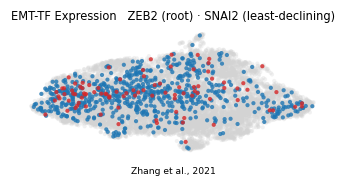

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
late_lab = 'late' if late_genuinely_terminal else 'least-declining'
ax.set_title(f'EMT-TF Expression   {early_tf} (root) · {late_tf} ({late_lab})', size=7.5)
ax.text(.5,-.14,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')